# CardioSense — Exploratory Data Analysis (EDA)

**Project:** CardioSense (Explainable ML System for 10-Year Coronary Heart Disease Risk Prediction)  
**Dataset:** `data/framingham.csv`  
**Target Variable:** `TenYearCHD` (Binary: `1` = developed CHD within 10 years, `0` = did not)

This notebook performs initial exploratory data analysis to understand the structure, data quality, class balance, feature distributions, correlations, and potential outliers in the Framingham Heart Study dataset before any preprocessing or modeling.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# Resolve project root whether run from project root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "framingham.csv").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "framingham.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Global plotting style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
PALETTE = {0: "#2B6CB0", 1: "#D94848"}

print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")
print(f"Reports dir:  {REPORTS_DIR}")


Project root: D:\Code\CardioSense
Data path:    D:\Code\CardioSense\data\framingham.csv
Reports dir:  D:\Code\CardioSense\reports


## 1. Data Loading & Initial Inspection

Let's load `data/framingham.csv` and inspect its dimensions (`shape`), column data types (`dtypes`), summary statistics, and the first few rows (`head()`).


In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("\nColumn data types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe().T.round(2))


Dataset shape: 4,238 rows x 16 columns

Column data types:

First 5 rows:

Summary statistics:


,dtype
male,int64
age,int64
education,float64
currentSmoker,int64
cigsPerDay,float64
BPMeds,float64
prevalentStroke,int64
prevalentHyp,int64
diabetes,int64
totChol,float64


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


,count,mean,std,min,25%,50%,75%,max
male,4238.0,0.43,0.50,0.00,0.00,0.0,1.00,1.0
age,4238.0,49.58,8.57,32.00,42.00,49.0,56.00,70.0
education,4133.0,1.98,1.02,1.00,1.00,2.0,3.00,4.0
currentSmoker,4238.0,0.49,0.50,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4209.0,9.00,11.92,0.00,0.00,0.0,20.00,70.0
BPMeds,4185.0,0.03,0.17,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4238.0,0.01,0.08,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4238.0,0.31,0.46,0.00,0.00,0.0,1.00,1.0
diabetes,4238.0,0.03,0.16,0.00,0.00,0.0,0.00,1.0
totChol,4188.0,236.72,44.59,107.00,206.00,234.0,263.00,696.0


### Interpretation — Data Structure & Types

- The dataset contains **4,238 patient records** and **16 columns** (15 clinical/demographic predictors plus the binary target `TenYearCHD`).
- All columns are stored numerically (`int64` or `float64`), so no string-to-numeric encoding is needed at load time.
- Notice that `education` (ordinal 1–4) and `BPMeds` (binary 0/1) are typed as `float64` solely because pandas represents integer columns containing `NaN` values as floats.
- Conceptually, the 15 predictors split into:
  - **8 continuous / count numeric measurements:** `age`, `cigsPerDay`, `totChol`, `sysBP`, `diaBP`, `BMI`, `heartRate`, `glucose`
  - **7 binary or ordinal indicators:** `male`, `education`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes`


## 2. Missing Values Analysis

Before deciding on an imputation or filtering strategy, we quantify missingness per column in both table form and a bar chart.


Total missing cells: 645
Rows with at least one missing value: 582 (13.73%)


,missing_count,missing_pct,non_null_count
glucose,388,9.16,3850
education,105,2.48,4133
BPMeds,53,1.25,4185
totChol,50,1.18,4188
cigsPerDay,29,0.68,4209
BMI,19,0.45,4219
heartRate,1,0.02,4237


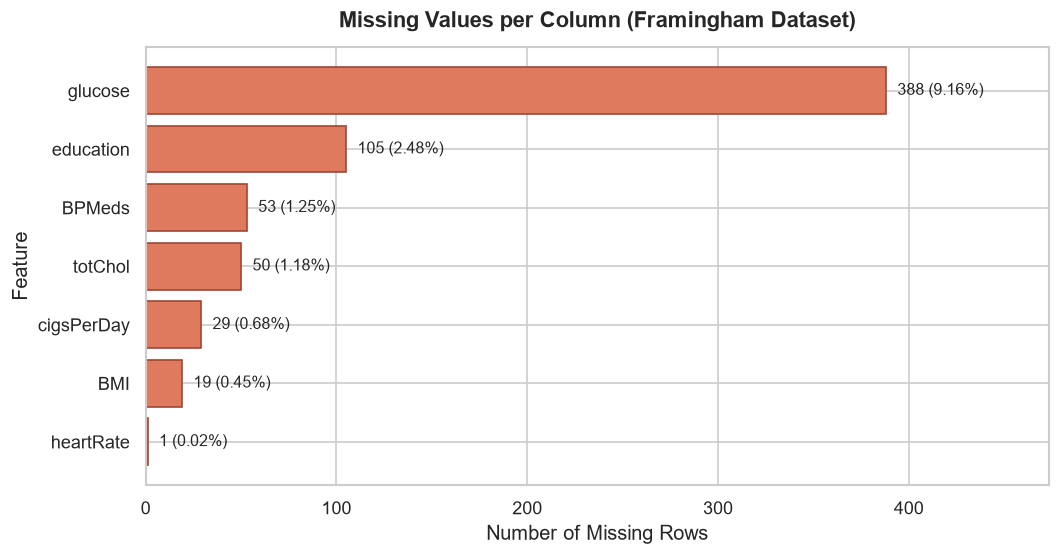

In [3]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df) * 100).round(2)

missing_df = (
    pd.DataFrame({
        "missing_count": missing_count,
        "missing_pct": missing_pct,
        "non_null_count": df.notnull().sum(),
    })
    .sort_values("missing_count", ascending=False)
)

rows_with_missing = df.isnull().any(axis=1).sum()
print(f"Total missing cells: {missing_count.sum():,}")
print(f"Rows with at least one missing value: {rows_with_missing:,} ({rows_with_missing / len(df) * 100:.2f}%)")
display(missing_df[missing_df["missing_count"] > 0])

# Bar chart of columns with missing values
missing_nonzero = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(missing_nonzero.index, missing_nonzero["missing_count"], color="#E07A5F", edgecolor="#9E4733")
ax.set_title("Missing Values per Column (Framingham Dataset)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Number of Missing Rows")
ax.set_ylabel("Feature")
ax.set_xlim(0, missing_nonzero["missing_count"].max() * 1.22)

for bar, (_, row) in zip(bars, missing_nonzero.iterrows()):
    ax.text(
        bar.get_width() + 6,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['missing_count'])} ({row['missing_pct']:.2f}%)",
        va="center",
        fontsize=9.5,
    )

plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_missing_values.png", bbox_inches="tight")
plt.show()


### Interpretation — Missing Values

- **7 of 16 columns** contain missing values, totaling **645 missing cells** across **582 rows (13.73% of the dataset)**. The target `TenYearCHD` has **0 missing values**.
- **`glucose` has by far the highest missingness** (`388` rows, `9.16%`), followed by `education` (`105`, `2.48%`), `BPMeds` (`53`, `1.25%`), `totChol` (`50`, `1.18%`), `cigsPerDay` (`29`, `0.68%`), `BMI` (`19`, `0.45%`), and `heartRate` (`1`, `0.02%`).
- **Modeling implication:** Dropping all rows with missing values would discard nearly **14% of our cohort** and risk biasing the sample. Instead, downstream pipelines should apply **imputation fitted strictly on the training split** (e.g., median imputation for skewed continuous features like `glucose`, mode/most-frequent for `education` and `BPMeds`), and we can evaluate adding a binary missingness indicator for `glucose`.


## 3. Duplicates Check

We verify whether the dataset contains exact duplicate patient rows that could leak information across train/test splits or distort summary statistics.


In [4]:
exact_dups = df.duplicated().sum()
feature_dups = df.drop(columns=["TenYearCHD"]).duplicated().sum()

print(f"Exact duplicate rows (all columns):       {exact_dups}")
print(f"Duplicate feature vectors (excl. target): {feature_dups}")


Exact duplicate rows (all columns):       0
Duplicate feature vectors (excl. target): 0


### Interpretation — Duplicates

- There are **0 exact duplicate rows** (and **0 duplicate feature vectors**) across all 4,238 records.
- No deduplication is needed, and we do not have duplicate-record data leakage concerns when partitioning into train and test sets.


## 4. Target Class Distribution (`TenYearCHD`)

Understanding the class balance of `TenYearCHD` is essential for selecting evaluation metrics and deciding on class-imbalance handling during modeling.


Class imbalance ratio (0 : 1) = 5.58 : 1


,label,count,percentage
0,No CHD (0),3594,84.8
1,10-Year CHD (1),644,15.2


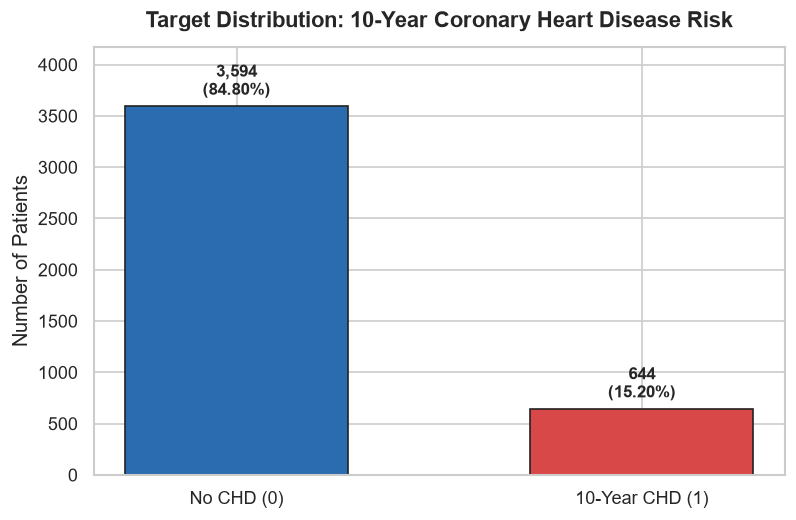

In [5]:
target_counts = df["TenYearCHD"].value_counts().sort_index()
target_pcts = (df["TenYearCHD"].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({
    "label": ["No CHD (0)", "10-Year CHD (1)"],
    "count": target_counts.values,
    "percentage": target_pcts.values,
})
display(target_summary)

imbalance_ratio = target_counts[0] / target_counts[1]
print(f"Class imbalance ratio (0 : 1) = {imbalance_ratio:.2f} : 1")

fig, ax = plt.subplots(figsize=(6.8, 4.5))
colors = [PALETTE[0], PALETTE[1]]
bars = ax.bar(target_summary["label"], target_summary["count"], color=colors, width=0.55, edgecolor="#222222")
ax.set_title("Target Distribution: 10-Year Coronary Heart Disease Risk", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Number of Patients")
ax.set_ylim(0, target_counts.max() * 1.16)

for bar, (_, row) in zip(bars, target_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 65,
        f"{int(row['count']):,}\n({row['percentage']:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_target_distribution.png", bbox_inches="tight")
plt.show()


### Interpretation — Target Class Distribution

- The dataset exhibits substantial **class imbalance**: **3,594 patients (84.80%)** did not develop CHD (`TenYearCHD = 0`), whereas **644 patients (15.20%)** did (`TenYearCHD = 1`) — an imbalance ratio of **5.58 : 1**.
- **Modeling implication:** Plain classification accuracy is a poor metric here because predicting `0` for every patient already yields **84.80%** accuracy while missing all positive cases. Future modeling should use **stratified train/test splits and cross-validation**, prioritize **PR-AUC, ROC-AUC, Recall, F1-score, and calibration**, and evaluate `class_weight="balanced"` or threshold tuning.


## 5. Distributions of Numeric Features Split by Target

We examine the 8 continuous/count numeric features (`age`, `cigsPerDay`, `totChol`, `sysBP`, `diaBP`, `BMI`, `heartRate`, `glucose`) stratified by `TenYearCHD` to see which physiological variables shift between positive and negative outcomes.


TenYearCHD              0       1
age        mean     48.77   54.15
           median   48.00   55.00
           std       8.41    8.01
cigsPerDay mean      8.71   10.63
           median    0.00    2.50
           std      11.69   13.01
totChol    mean    235.17  245.39
           median  232.00  241.00
           std      43.77   48.08
sysBP      mean    130.33  143.62
           median  127.00  139.00
           std      20.46   26.69
diaBP      mean     82.16   86.98
           median   81.00   85.50
           std      11.34   14.03
BMI        mean     25.67   26.53
           median   25.25   26.16
           std       3.98    4.52
heartRate  mean     75.76   76.53
           median   75.00   75.00
           std      11.99   12.22
glucose    mean     80.68   89.01
           median   78.00   79.00
           std      18.97   41.14

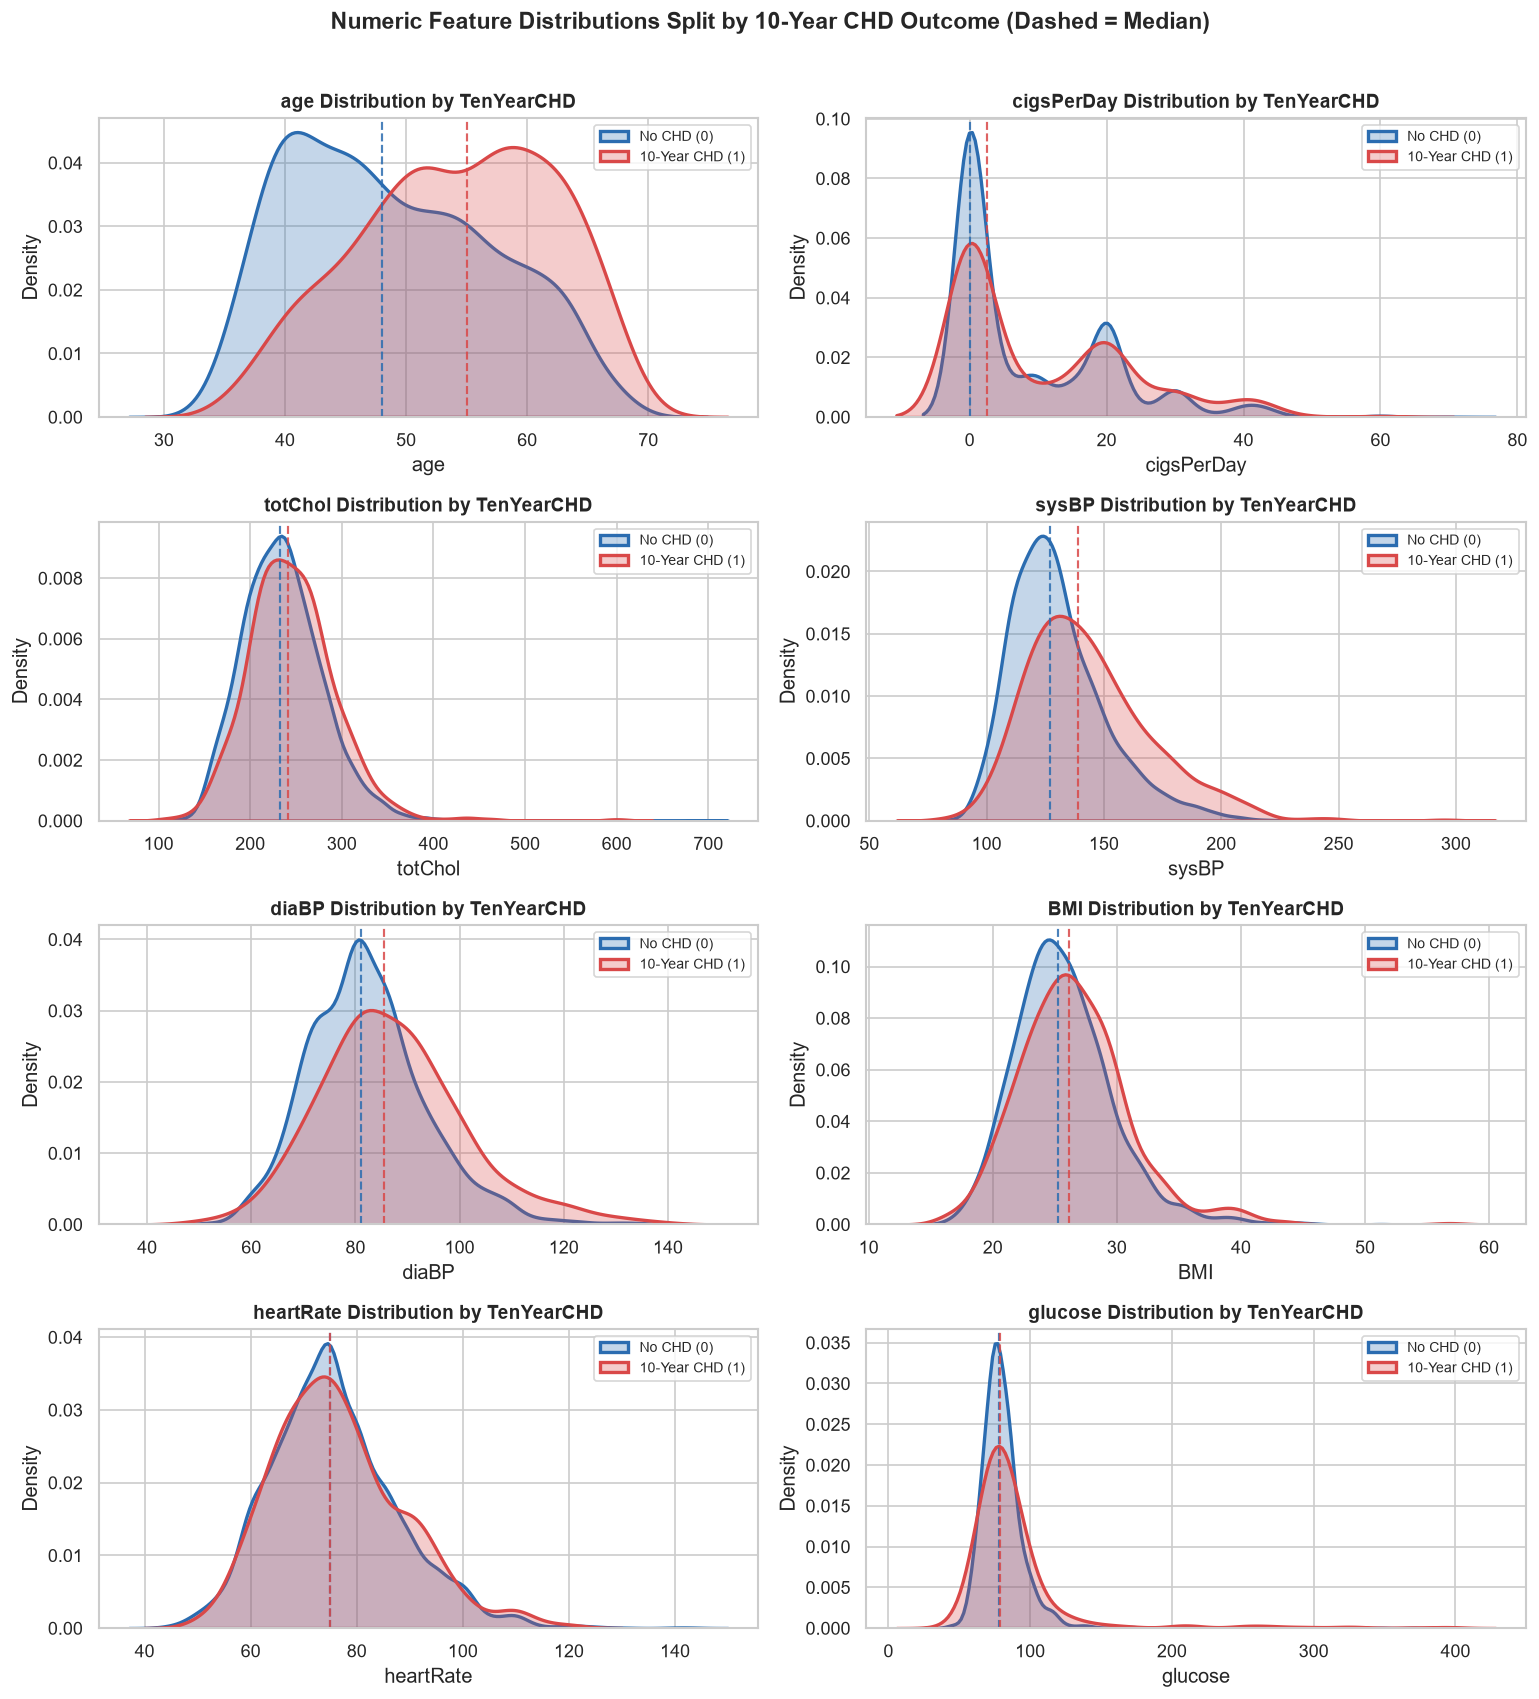

In [6]:
numeric_cols = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]

group_stats = (
    df.groupby("TenYearCHD")[numeric_cols]
    .agg(["mean", "median", "std"])
    .round(2)
)
display(group_stats.T)

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    for label, name in [(0, "No CHD (0)"), (1, "10-Year CHD (1)")]:
        subset = df.loc[df["TenYearCHD"] == label, col].dropna()
        sns.kdeplot(
            subset,
            ax=ax,
            label=name,
            color=PALETTE[label],
            fill=True,
            alpha=0.28,
            linewidth=2,
            common_norm=False,
        )
        ax.axvline(subset.median(), color=PALETTE[label], linestyle="--", linewidth=1.3, alpha=0.85)
    ax.set_title(f"{col} Distribution by TenYearCHD", fontsize=11.5, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend(frameon=True, fontsize=8.5)

fig.suptitle("Numeric Feature Distributions Split by 10-Year CHD Outcome (Dashed = Median)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_numeric_distributions_by_target.png", bbox_inches="tight")
plt.show()


### Interpretation — Numeric Feature Distributions by Target

- **Strongest distributional shifts (`TenYearCHD = 1` vs `0`):**
  - **`age`:** Positive cases are noticeably older (median **55 vs. 48** years; mean **54.15 vs. 48.77**).
  - **`sysBP` & `diaBP`:** Systolic BP shows a clear rightward shift in CHD cases (median **139.0 vs. 127.0** mmHg; mean **143.62 vs. 130.33**), and diastolic BP also shifts upward (median **85.5 vs. 81.0** mmHg).
  - **`totChol` & `BMI`:** Total cholesterol (median **241.0 vs. 232.0** mg/dL) and BMI (median **26.16 vs. 25.25**) are modestly higher in the positive class.
- **Skewness & zero-inflation:**
  - **`glucose`** is strongly right-skewed with a long upper tail (mean **89.01 vs. 80.68** mg/dL, even though medians are close at **79 vs. 78**), reflecting diabetic/hyperglycemic high-risk patients.
  - **`cigsPerDay`** is heavily zero-inflated (representing non-smokers) with peaks around 10, 20, and 30 cigarettes/day (mean **10.63 vs. 8.71**).
- **`heartRate`** shows almost identical distributions across both classes (median **75 bpm** in both), suggesting weak standalone linear discrimination.


## 6. Correlation Heatmap

We compute Pearson correlations across all 16 variables to identify features most associated with `TenYearCHD` and check for multicollinearity among predictors.


Pearson correlation with TenYearCHD:


,corr_with_TenYearCHD
age,0.2253
sysBP,0.2164
prevalentHyp,0.1776
diaBP,0.1453
glucose,0.1255
diabetes,0.0973
male,0.0884
BPMeds,0.0875
totChol,0.0822
BMI,0.0752


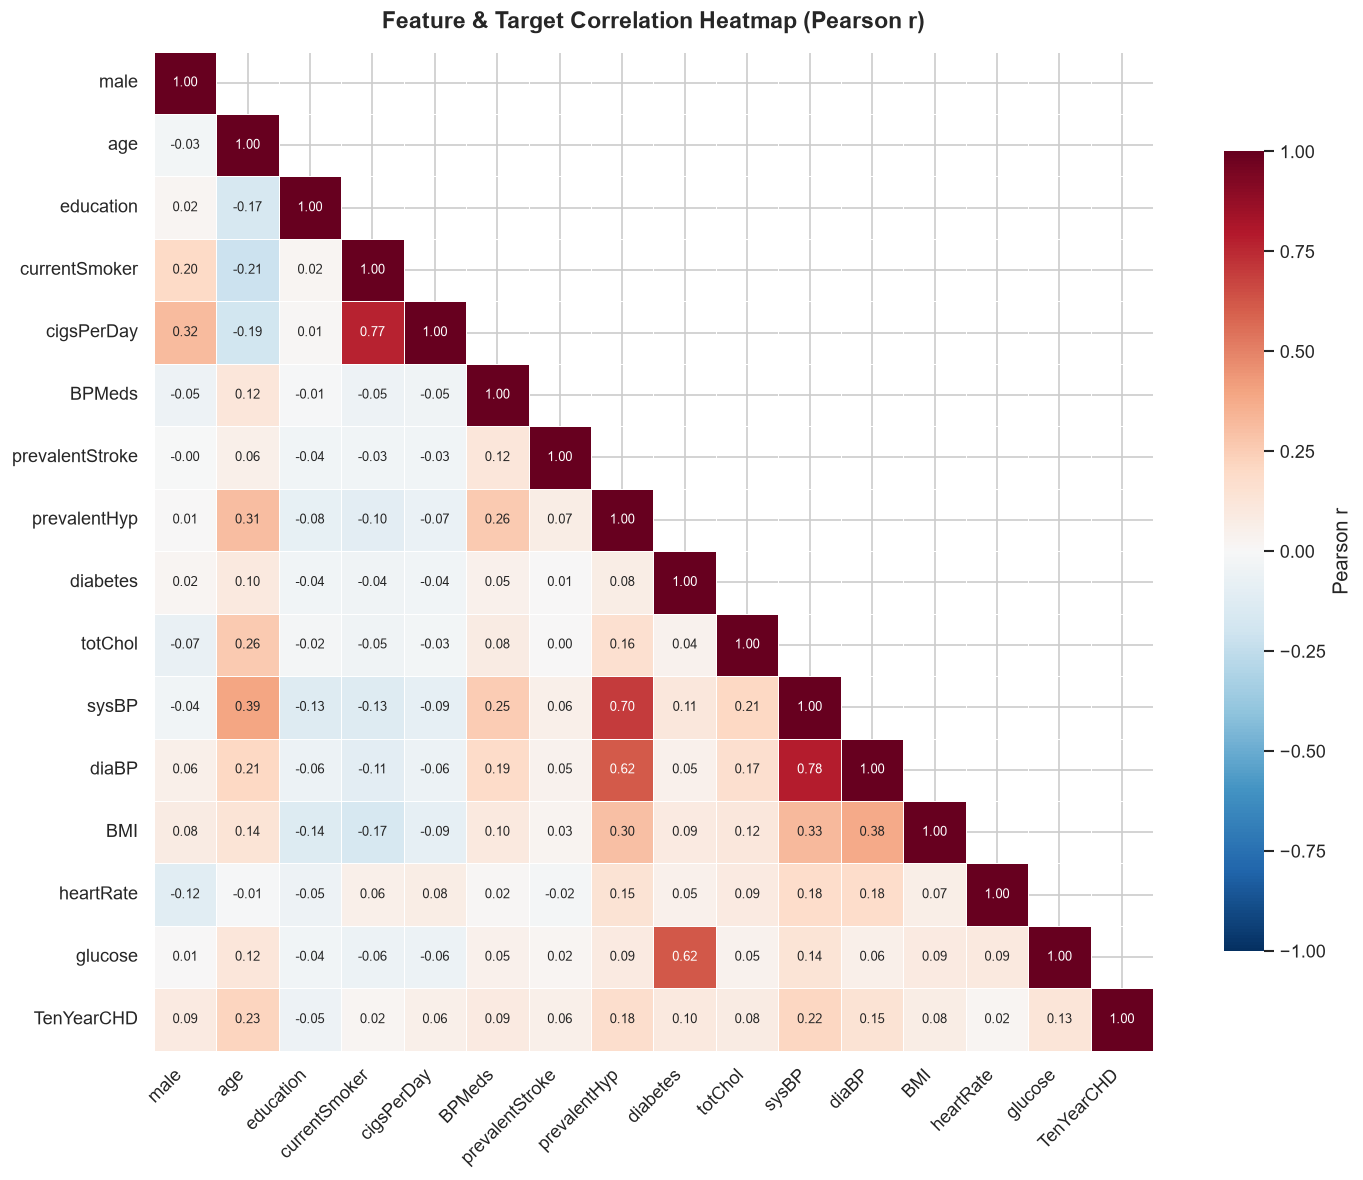

In [7]:
corr_matrix = df.corr(numeric_only=True)

target_corr = corr_matrix["TenYearCHD"].drop("TenYearCHD").sort_values(ascending=False)
print("Pearson correlation with TenYearCHD:")
display(target_corr.to_frame("corr_with_TenYearCHD").round(4))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"},
    annot_kws={"size": 8},
    ax=ax,
)
ax.set_title("Feature & Target Correlation Heatmap (Pearson r)", fontsize=14, fontweight="bold", pad=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_correlation_heatmap.png", bbox_inches="tight")
plt.show()


### Interpretation — Correlation Heatmap

- **Strongest linear associations with `TenYearCHD`:** `age` (**+0.23**), `sysBP` (**+0.22**), `prevalentHyp` (**+0.18**), `diaBP` (**+0.15**), `glucose` (**+0.13**), and `diabetes` (**+0.10**). `education` shows a slight negative correlation (**-0.05**). No single feature dominates linearly, reinforcing the value of multivariable ML models.
- **Notable predictor multicollinearity:**
  - `sysBP` and `diaBP` (**r = 0.78**), and both correlate strongly with `prevalentHyp` (`sysBP` ~0.70, `diaBP` ~0.62).
  - `currentSmoker` and `cigsPerDay` (**r = 0.77**), since non-smokers have `cigsPerDay = 0`.
  - `diabetes` and `glucose` (**r = 0.62**).
- **Explainability note:** Because several clinical pairs are strongly collinear, linear model coefficients and feature-importance attributions (such as SHAP values) can split credit across correlated pairs; this should be considered during feature selection and explanation reporting.


## 7. Outlier Detection via Boxplots

We inspect boxplots and interquartile range (IQR) outlier counts for the 8 continuous numeric features to distinguish plausible clinical extremes from potential data anomalies.


,feature,Q1,median,Q3,lower_fence,upper_fence,min,max,iqr_outliers,outlier_pct
7,glucose,71.00,78.0,87.00,47.00,111.00,40.00,394.0,188,4.88
3,sysBP,117.00,128.0,144.00,76.50,184.50,83.50,295.0,126,2.97
5,BMI,23.07,25.4,28.04,15.62,35.49,15.54,56.8,97,2.30
4,diaBP,75.00,82.0,89.88,52.69,112.19,48.00,142.5,81,1.91
6,heartRate,68.00,75.0,83.00,45.50,105.50,44.00,143.0,76,1.79
2,totChol,206.00,234.0,263.00,120.50,348.50,107.00,696.0,56,1.34
1,cigsPerDay,0.00,0.0,20.00,-30.00,50.00,0.00,70.0,12,0.29
0,age,42.00,49.0,56.00,21.00,77.00,32.00,70.0,0,0.00


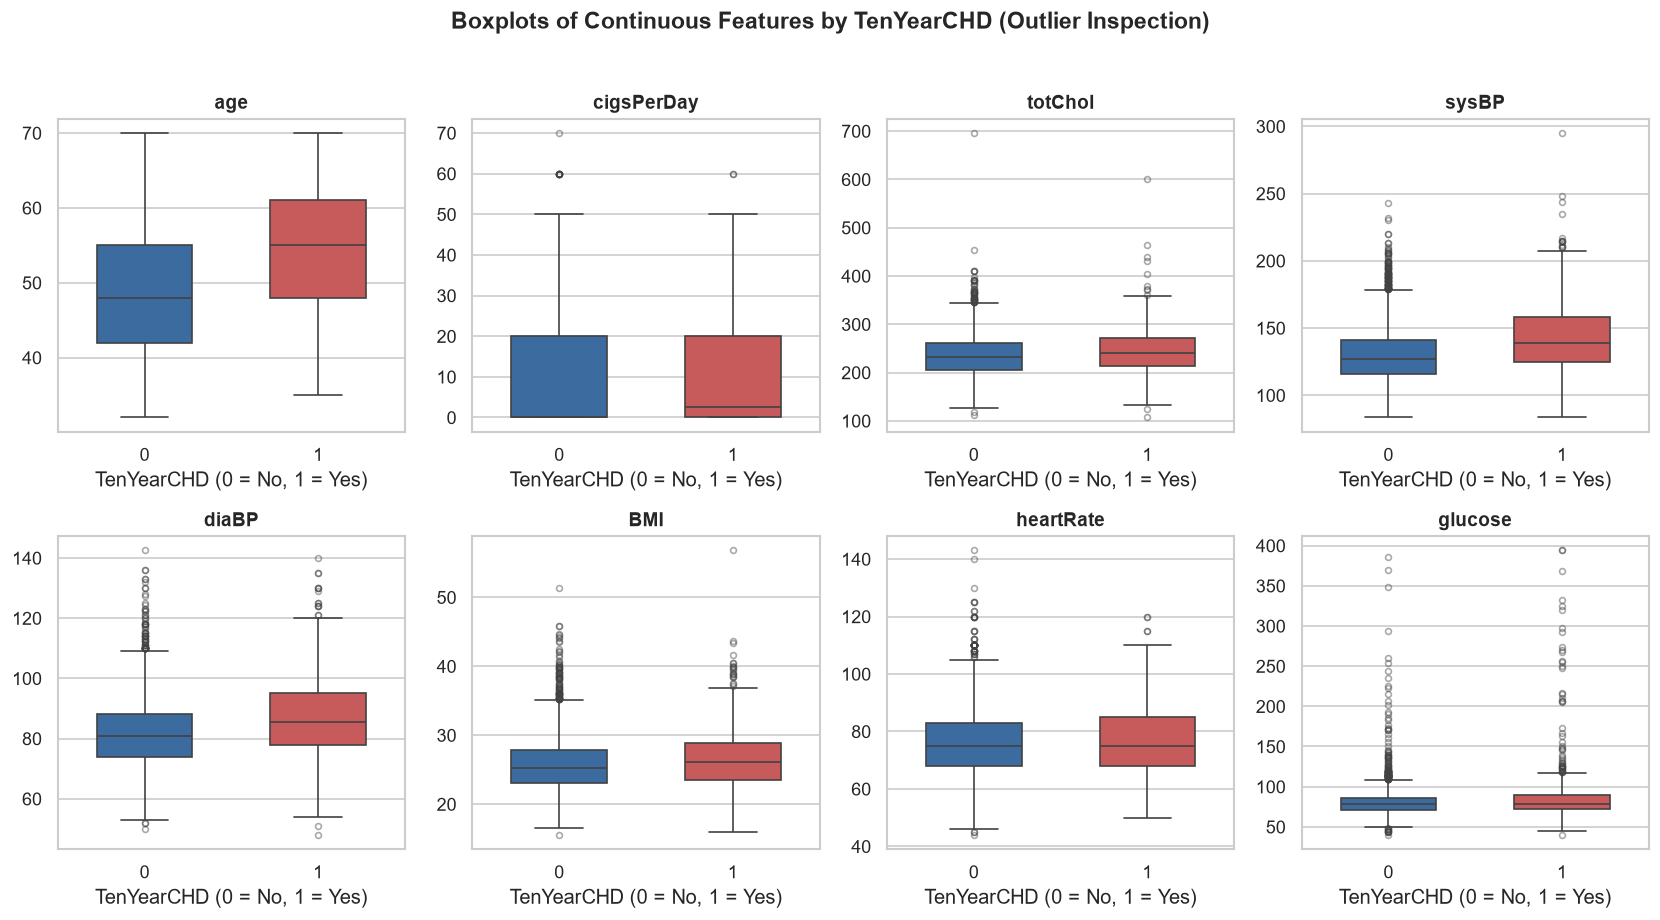

In [8]:
outlier_rows = []
for col in numeric_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        "feature": col,
        "Q1": round(q1, 2),
        "median": round(s.median(), 2),
        "Q3": round(q3, 2),
        "lower_fence": round(lower, 2),
        "upper_fence": round(upper, 2),
        "min": round(s.min(), 2),
        "max": round(s.max(), 2),
        "iqr_outliers": n_out,
        "outlier_pct": round(n_out / len(s) * 100, 2),
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("iqr_outliers", ascending=False)
display(outlier_summary)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=df,
        x="TenYearCHD",
        y=col,
        hue="TenYearCHD",
        palette=[PALETTE[0], PALETTE[1]],
        legend=False,
        width=0.55,
        flierprops={"marker": "o", "markersize": 3.5, "alpha": 0.45},
        ax=ax,
    )
    ax.set_title(col, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("TenYearCHD (0 = No, 1 = Yes)")
    ax.set_ylabel("")

fig.suptitle("Boxplots of Continuous Features by TenYearCHD (Outlier Inspection)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_boxplots_outliers.png", bbox_inches="tight")
plt.show()


### Interpretation — Outliers & Boxplots

- Under the standard $1.5 \times \text{IQR}$ rule, **`glucose`** has the highest outlier share (**188 values / 4.88%**, up to **394 mg/dL**), followed by **`sysBP`** (**126 / 2.97%**, up to **295 mmHg**), **`BMI`** (**97 / 2.30%**, up to **56.8**), **`diaBP`** (**81 / 1.91%**, up to **142.5 mmHg**), **`heartRate`** (**76 / 1.79%**, up to **143 bpm**), **`totChol`** (**56 / 1.34%**, up to **696 mg/dL**), and **`cigsPerDay`** (**12 / 0.29%**, up to **70/day**). **`age`** has **0 outliers** (range **32–70**).
- Most flagged points are **upper-tail clinical extremes** (e.g., severe hypertension, hyperglycemia in diabetic patients, heavy smoking) rather than negative or impossible values.
- A few very extreme observations — notably `totChol` up to **696 mg/dL** and `sysBP` at **295 mmHg** — warrant sensitivity checks, but blindly deleting IQR outliers would strip away high-risk patients that the model needs to recognize. Using **tree-based models** or **robust scaling** (`RobustScaler`) / log-transforms for skewed features (`glucose`) is a safer strategy.


## 8. Final EDA Summary

### Data Analysis Key Findings
- **Dataset integrity:** `data/framingham.csv` contains **4,238 records** and **16 numeric columns** with **0 duplicate rows** and **0 missing target labels**.
- **Missingness concentration:** **645 missing values** affect **582 rows (13.73%)**, driven primarily by `glucose` (**388 / 9.16%**) and `education` (**105 / 2.48%**).
- **Class imbalance:** `TenYearCHD` is imbalanced at **84.80% negative (3,594)** vs. **15.20% positive (644)** (**5.58 : 1**).
- **Key risk signals & collinearity:** `age` (*r* = 0.23), `sysBP` (*r* = 0.22), `prevalentHyp` (*r* = 0.18), `diaBP` (*r* = 0.15), and `glucose` (*r* = 0.13) show the strongest positive separation for 10-year CHD. Strong collinearity exists between `sysBP`/`diaBP` (*r* = 0.78), `currentSmoker`/`cigsPerDay` (*r* = 0.77), and `diabetes`/`glucose` (*r* = 0.62).
- **Clinical outliers:** Upper-tail outliers are prominent in `glucose` (4.88%) and `sysBP` (2.97%), representing genuine high-risk clinical profiles rather than simple data corruption.

### Insights & Next Steps
- **Preprocessing design:** Use stratified train/test splitting first, then fit train-only imputation (median for skewed continuous features, mode for `education`/`BPMeds`, plus testing a `glucose_missing` flag) and robust scaling or log transformation where appropriate.
- **Evaluation & explainability readiness:** Evaluate upcoming baseline and tree models with **ROC-AUC, PR-AUC, Recall, F1, and calibration curves**, and account for correlated feature pairs (`sysBP`/`diaBP`, `currentSmoker`/`cigsPerDay`, `diabetes`/`glucose`) when interpreting SHAP/feature importance.
